# 04 — Weak score targets and architecture feasibility

Perera E. V. · J26-DS-339 · R007–R008. This executed notebook explains feature preparation and a five-epoch pilot. The target is original MIDI pitch class, **not verified performed pitch**. The fixed cohort contains 20 TRAIN and 10 previously inspected VALID recordings; TEST remains reserved.

In [1]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'src/melody_understanding').exists())
data=json.loads((ROOT/'experiments/vishwa/results/weak_score_dataset.json').read_text())
results=json.loads((ROOT/'experiments/vishwa/results/score_model_pilot.json').read_text())
print('Frames:',data['frames_by_split'])
print('Supervised:',data['supervised_frames_by_split'])
print('Training configuration:',results['config'])


Frames: {'TRAIN': 26157, 'VALID': 12817}
Supervised: {'TRAIN': 15120, 'VALID': 7382}
Training configuration: {'seed': 339, 'epochs': 5, 'batch_size': 8, 'window_frames': 256, 'learning_rate': 0.001, 'device': 'cpu', 'threads': 2, 'selection': 'fixed last epoch; no validation selection'}


## Step 1: aligned features and explicit supervision

Audio is resampled to 22050 Hz without trimming. An 80-band Mel spectrogram uses a 4096-sample window and 256-sample hop. Each frame receives rest=0 or MIDI pitch class+1. A fixed 100 ms mask excludes note/recording boundaries. This removes potentially ambiguous frames but does not correct alignment. Per-band normalization is fitted on TRAIN only. Tensors and checkpoints remain local and ignored by Git.

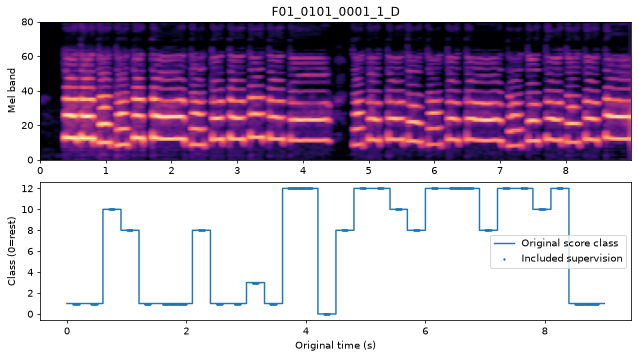

In [2]:
row=data['recordings'][0]
with np.load(ROOT/row['path']) as z: features={k:z[k] for k in z.files}
fig,axes=plt.subplots(2,1,figsize=(9,5),dpi=70,constrained_layout=True)
t=features['times_s']
axes[0].imshow(features['mel_db'],origin='lower',aspect='auto',extent=[t[0],t[-1],0,80],cmap='magma');axes[0].set(ylabel='Mel band',title=row['key'])
axes[1].step(t,features['score_class'],where='post',label='Original score class')
keep=features['supervision_mask'];axes[1].scatter(t[keep],features['score_class'][keep],s=2,label='Included supervision')
axes[1].set(xlabel='Original time (s)',ylabel='Class (0=rest)');axes[1].legend();plt.show()


## Step 2: fixed-budget comparison

The CNN uses two temporal convolution layers. The hybrid adds one self-attention layer and sinusoidal positions. Both predict the same 13 classes, train with the same data ordering and five-epoch budget, and use the final epoch. The majority baseline always predicts the most frequent supervised TRAIN class. Accuracy and F1 here are different from earlier onset-sensitive note F1 and must not be compared directly.

majority           TRAIN recording-macro accuracy=0.1602; pooled accuracy=0.1634; macro F1=0.0216
majority           VALID recording-macro accuracy=0.1210; pooled accuracy=0.1260; macro F1=0.0203
pYIN               TRAIN recording-macro accuracy=0.5853; pooled accuracy=0.5966; macro F1=0.5006
pYIN               VALID recording-macro accuracy=0.4855; pooled accuracy=0.5305; macro F1=0.4965
cnn                TRAIN recording-macro accuracy=0.5848; pooled accuracy=0.5989; macro F1=0.3903
cnn                VALID recording-macro accuracy=0.4253; pooled accuracy=0.4889; macro F1=0.3455
cnn_transformer    TRAIN recording-macro accuracy=0.6011; pooled accuracy=0.6110; macro F1=0.4182
cnn_transformer    VALID recording-macro accuracy=0.3945; pooled accuracy=0.4561; macro F1=0.3108
cnn parameters: 18413
cnn_transformer parameters: 31117


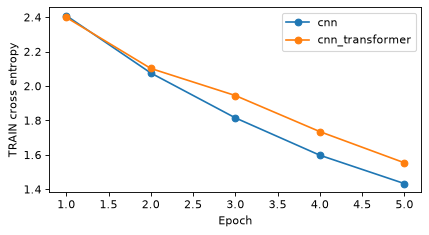

In [3]:
rows=[('majority',results['majority']),('pYIN',results['pyin'])]+[(name,row['scores']) for name,row in results['models'].items()]
for name,scores in rows:
    for split,score in scores.items():
        print(f"{name:18s} {split:5s} recording-macro accuracy={score['recording_macro_accuracy']:.4f}; pooled accuracy={score['frame_accuracy']:.4f}; macro F1={score['macro_f1_reference_present_classes']:.4f}")
fig,ax=plt.subplots(figsize=(6,3),dpi=80)
for name,row in results['models'].items():
    ax.plot([r['epoch'] for r in row['history']],[r['training_loss'] for r in row['history']],marker='o',label=name)
    print(name,'parameters:',row['parameters'])
ax.set(xlabel='Epoch',ylabel='TRAIN cross entropy');ax.legend();plt.show()


## Step 3: interpretation and research decision

A falling TRAIN loss only demonstrates optimization on this target. Compare VALID against the majority baseline before claiming useful learning. A hybrid with more parameters cannot establish an attention benefit from one small run. Any weak-score result remains distinct from performed-pitch transcription, full note events, CFP features, beat/key/phrase tasks, and harmony embeddings.

Next priority: human listening and reference review of the flagged TRAIN recordings, followed by a justified target policy and a preregistered expanded, repeated-seed comparison. Do not expand training solely to obtain a favorable validation score.